<a href="https://colab.research.google.com/github/alebri2506/notebooks-Machine_Learning-Sismos.ipynb/blob/main/dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd # Biblioteca que permite generar dataset o dataframe
import numpy as np #Biblioteca, array, matrices, elabora dataset atraves de listas
import seaborn as sns #Seaborn es una biblioteca de visualización basada en matplotlib.

# https://www.datosabiertos.gob.pe/dataset/cat%C3%A1logo-s%C3%ADsmico-1960-2023-instituto-geof%C3%ADsico-del-per%C3%BA-igp

sismos = pd.read_excel('/content/Catalogo1960_2023.xlsx')


In [ ]:
sismos

,ID,FECHA_UTC,HORA_UTC,LATITUD,LONGITUD,PROFUNDIDAD,MAGNITUD,FECHA_CORTE
0,0,19600113,154034,-16.145,-72.144,60,7.5,20223006
1,1,19600115,93024,-15.000,-75.000,70,7.0,20223006
2,2,19600117,25758,-14.500,-74.500,150,6.4,20223006
3,3,19600123,33732,-12.500,-68.500,300,5.8,20223006
4,4,19600130,50724,-5.500,-77.500,100,5.7,20223006
...,...,...,...,...,...,...,...,...
23675,23675,20231231,170836,-9.670,-75.630,125,4.0,20240101
23676,23676,20230223,61804,-8.690,-77.810,15,4.3,20240101
23677,23677,20230303,193913,-6.890,-80.230,43,4.3,20240101
23678,23678,20230327,201313,-10.530,-74.700,134,4.6,20240101


LIMPIEZA DE DATOS

In [ ]:
# Visualizar tipos de datos
sismos.dtypes

,0
ID,int64
FECHA_UTC,int64
HORA_UTC,int64
LATITUD,float64
LONGITUD,float64
PROFUNDIDAD,int64
MAGNITUD,float64
FECHA_CORTE,int64


In [ ]:
# Mostrar datos nulos
sismos.isnull().sum()

,0
ID,0
FECHA_UTC,0
HORA_UTC,0
LATITUD,0
LONGITUD,0
PROFUNDIDAD,0
MAGNITUD,0
FECHA_CORTE,0


In [ ]:
# Filas duplicadas
sismos.duplicated().sum()

np.int64(0)

In [ ]:
# Eliminacion de columnas
sismos = sismos.drop(['ID', 'FECHA_CORTE','HORA_UTC'], axis=1)

In [ ]:
sismos

,FECHA_UTC,LATITUD,LONGITUD,PROFUNDIDAD,MAGNITUD
0,19600113,-16.145,-72.144,60,7.5
1,19600115,-15.000,-75.000,70,7.0
2,19600117,-14.500,-74.500,150,6.4
3,19600123,-12.500,-68.500,300,5.8
4,19600130,-5.500,-77.500,100,5.7
...,...,...,...,...,...
23675,20231231,-9.670,-75.630,125,4.0
23676,20230223,-8.690,-77.810,15,4.3
23677,20230303,-6.890,-80.230,43,4.3
23678,20230327,-10.530,-74.700,134,4.6


In [ ]:
sismos['FECHA_UTC'] = pd.to_datetime(sismos['FECHA_UTC'], format='%Y%m%d', errors='coerce')

# Extraer AÑO y MES
sismos['AÑO'] = sismos['FECHA_UTC'].dt.year
sismos['MES'] = sismos['FECHA_UTC'].dt.month

In [ ]:
# Clasificar la profundidad
def clasificar_profundidad(p):
    if pd.isna(p):
        return None
    elif p <= 60:
        return 'Superficial'
    elif p <= 300:
        return 'Intermedio'
    else:
        return 'Profundo'

sismos['TIPO_PROFUNDIDAD'] = sismos['PROFUNDIDAD'].apply(clasificar_profundidad)

In [ ]:
sismos

,FECHA_UTC,LATITUD,LONGITUD,PROFUNDIDAD,MAGNITUD,AÑO,MES,TIPO_PROFUNDIDAD
0,1960-01-13,-16.145,-72.144,60,7.5,1960,1,Superficial
1,1960-01-15,-15.000,-75.000,70,7.0,1960,1,Intermedio
2,1960-01-17,-14.500,-74.500,150,6.4,1960,1,Intermedio
3,1960-01-23,-12.500,-68.500,300,5.8,1960,1,Intermedio
4,1960-01-30,-5.500,-77.500,100,5.7,1960,1,Intermedio
...,...,...,...,...,...,...,...,...
23675,2023-12-31,-9.670,-75.630,125,4.0,2023,12,Intermedio
23676,2023-02-23,-8.690,-77.810,15,4.3,2023,2,Superficial
23677,2023-03-03,-6.890,-80.230,43,4.3,2023,3,Superficial
23678,2023-03-27,-10.530,-74.700,134,4.6,2023,3,Intermedio


In [ ]:
# Eliminacion de columnas inecesarias
sismos = sismos.drop(['FECHA_UTC','PROFUNDIDAD'], axis=1)

In [ ]:
sismos

,LATITUD,LONGITUD,MAGNITUD,AÑO,MES,TIPO_PROFUNDIDAD
0,-16.145,-72.144,7.5,1960,1,Superficial
1,-15.000,-75.000,7.0,1960,1,Intermedio
2,-14.500,-74.500,6.4,1960,1,Intermedio
3,-12.500,-68.500,5.8,1960,1,Intermedio
4,-5.500,-77.500,5.7,1960,1,Intermedio
...,...,...,...,...,...,...
23675,-9.670,-75.630,4.0,2023,12,Intermedio
23676,-8.690,-77.810,4.3,2023,2,Superficial
23677,-6.890,-80.230,4.3,2023,3,Superficial
23678,-10.530,-74.700,4.6,2023,3,Intermedio


<Axes: >

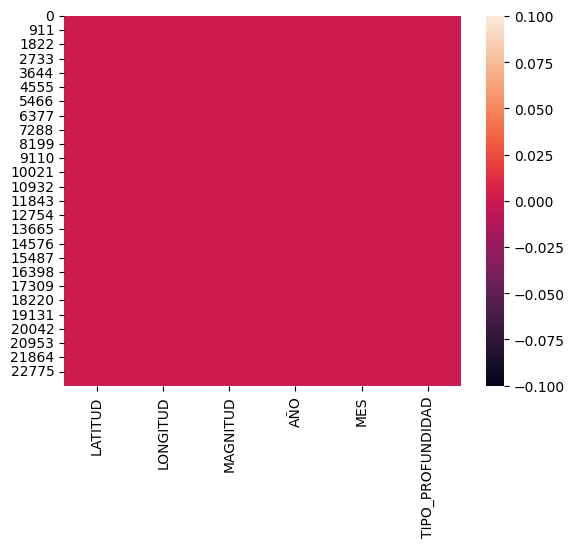

In [ ]:
sns.heatmap(sismos.isnull())


In [ ]:
# Definición de las columnas trabajadas
columnas_base = ['LATITUD', 'LONGITUD', 'MAGNITUD', 'AÑO', 'MES', 'TIPO_PROFUNDIDAD']

# Número de filas sucias a generar
n_sucias = 200

# 1. Crear DataFrame base con valores válidos
filas_sucias = pd.DataFrame({
    'LATITUD': np.random.uniform(-18.0, -3.0, n_sucias),
    'LONGITUD': np.random.uniform(-81.0, -68.0, n_sucias),
    'MAGNITUD': np.round(np.random.uniform(4.5, 7.5, n_sucias), 1),
    'AÑO': np.random.randint(2000, 2025, n_sucias),
    'MES': np.random.randint(1, 13, n_sucias),
    'TIPO_PROFUNDIDAD': np.random.choice(['Superficial', 'Intermedio', 'Profundo'], n_sucias)
})

# 2. Introducir errores aleatorios en el DataFrame sucio

# Iterar por cada columna base para simular errores
for col in columnas_base:
    # Seleccionar aleatoriamente el 25% de las filas para introducir errores en esta columna
    indices = np.random.choice(filas_sucias.index, size=int(0.25 * n_sucias), replace=False)

    for idx in indices:
        # Elegir aleatoriamente el tipo de error a insertar
        error = np.random.choice(['nan', 'string', 'negativo', 'fuera_de_rango'])

        # Insertar un valor faltante (NaN)
        if error == 'nan':
            filas_sucias.at[idx, col] = np.nan

        # Insertar un texto inválido (simula dato corrupto tipo string)
        elif error == 'string':
            filas_sucias.at[idx, col] = 'error'

        # Insertar valor negativo en columnas numéricas donde no debería haber
        elif error == 'negativo' and col in ['MAGNITUD', 'AÑO', 'MES']:
            filas_sucias.at[idx, col] = -1 * abs(filas_sucias.at[idx, col])

        # Insertar un valor fuera de los rangos válidos según la columna
        elif error == 'fuera_de_rango':
            if col == 'LATITUD':
                filas_sucias.at[idx, col] = np.random.uniform(30, 90)  # Latitud fuera de Perú
            elif col == 'LONGITUD':
                filas_sucias.at[idx, col] = np.random.uniform(100, 180)  # Longitud fuera de Perú
            elif col == 'MES':
                filas_sucias.at[idx, col] = np.random.randint(13, 30)  # Mes inválido
            elif col == 'TIPO_PROFUNDIDAD':
                filas_sucias.at[idx, col] = 'Desconocido'  # Categoría no contemplada

# 3. Crear una nueva variable con el dataset combinado
dataset_final_con_sucios = pd.concat([sismos, filas_sucias], ignore_index=True)

print("Dataset combinado creado en la variable 'dataset_final_con_sucios'")

print("Cantidad de filas en el dataset original:", len(sismos))
print("Cantidad de filas agregadas con datos sucios:", len(filas_sucias))
print("Total final en 'dataset_final_con_sucios':", len(dataset_final_con_sucios))

In [ ]:
df_limpio = dataset_final_con_sucios.copy()

# Convertir columnas numéricas (forzar errores a NaN)
for col in ['LATITUD', 'LONGITUD', 'MAGNITUD', 'AÑO', 'MES']:
    df_limpio[col] = pd.to_numeric(df_limpio[col], errors='coerce')

# MAGNITUD válida entre 0 y 9
df_limpio = df_limpio[(df_limpio['MAGNITUD'] >= 0) & (df_limpio['MAGNITUD'] <= 9)]

# AÑO: no negativo ni futuro irreal
df_limpio = df_limpio[(df_limpio['AÑO'] >= 0) & (df_limpio['AÑO'] <= 2025)]

# MES válido entre 1 y 12
df_limpio = df_limpio[(df_limpio['MES'] >= 1) & (df_limpio['MES'] <= 12)]

# LATITUD y LONGITUD válidas para Perú
df_limpio = df_limpio[(df_limpio['LATITUD'] >= -18) & (df_limpio['LATITUD'] <= -3)]
df_limpio = df_limpio[(df_limpio['LONGITUD'] >= -81) & (df_limpio['LONGITUD'] <= -68)]

# -------------------------------
# LIMPIEZA de TIPO_PROFUNDIDAD
# -------------------------------

# Reemplazar valores inválidos por NaN
df_limpio['TIPO_PROFUNDIDAD'] = df_limpio['TIPO_PROFUNDIDAD'].replace(
    ['error', 'Error', 'desconocido', 'Desconocido', '', ' '], np.nan
)

# Calcular moda
modo_tipo = df_limpio['TIPO_PROFUNDIDAD'].mode()[0]

# Rellenar NaN con la moda
df_limpio['TIPO_PROFUNDIDAD'] = df_limpio['TIPO_PROFUNDIDAD'].fillna(modo_tipo)

# -------------------------------
# Rellenar MAGNITUD faltante con la mediana
# -------------------------------
mediana_magnitud = df_limpio['MAGNITUD'].median()
df_limpio['MAGNITUD'] = df_limpio['MAGNITUD'].fillna(mediana_magnitud)

# Eliminar cualquier otro NaN restante
df_limpio = df_limpio.dropna()

print("Filas finales después de la limpieza:", len(df_limpio))


In [ ]:
df_limpio

In [ ]:
df_limpio['AÑO'] = df_limpio['AÑO'].astype(int)
df_limpio['MES'] = df_limpio['MES'].astype(int)

In [ ]:
df_limpio

<Axes: xlabel='TIPO_PROFUNDIDAD', ylabel='MAGNITUD'>

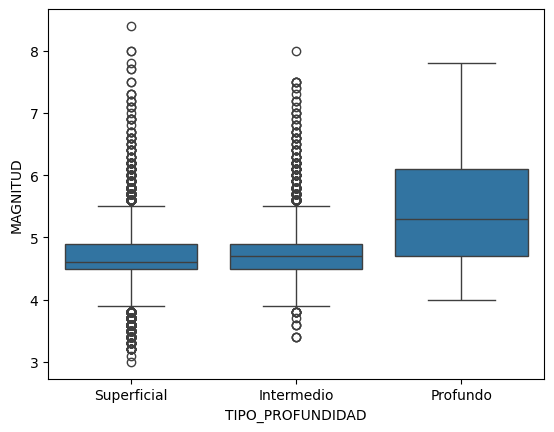

In [ ]:
# Este gráfico muestra cómo varía la magnitud sísmica según el tipo de profundidad.
sns.boxplot(data=df_limpio, x='TIPO_PROFUNDIDAD', y='MAGNITUD')

PLANTEAMIENTO DE MODELO

¿Qué magnitud sísmica podría presentarse en una ubicación del Perú, considerando su historial de eventos registrados en coordenadas similares?

In [ ]:
sismos.head()

,LATITUD,LONGITUD,MAGNITUD,AÑO,MES,TIPO_PROFUNDIDAD
0,-16.145,-72.144,7.5,1960,1,Superficial
1,-15.000,-75.000,7.0,1960,1,Intermedio
2,-14.500,-74.500,6.4,1960,1,Intermedio
3,-12.500,-68.500,5.8,1960,1,Intermedio
4,-5.500,-77.500,5.7,1960,1,Intermedio


In [ ]:
from re import VERBOSE
# Paso 1: Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Paso 2: Renombrar columnas a minúscula (más manejable)
sismos.columns = ['latitud', 'longitud', 'magnitud', 'año', 'mes', 'tipo_profundidad']

# Paso 3: Codificar la variable categórica tipo_profundidad
df = pd.get_dummies(sismos, columns=['tipo_profundidad'])

# Paso 4: Separar variables independientes (X) y dependiente (y)
X = df.drop('magnitud', axis=1)
y = df['magnitud']

# Guardar el orden y nombres exactos de las columnas
columnas_esperadas = X.columns.tolist()

# Paso 5: Escalar variables numéricas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Paso 6: Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Paso 7: Crear red neuronal
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)  # Salida para regresión
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Entrenando modelo...")
# Paso 8: Entrenar modelo (80% datos + validar con 20% test)
history = model.fit(X_train, y_train,
                    epochs=300,
                    batch_size=32,
                    validation_data=(X_test, y_test),verbose=False)
print("Modelo entrenado.")


Entrenando modelo...
Modelo entrenado.


148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1311 - mae: 0.2503
MAE (Error absoluto medio): 0.25


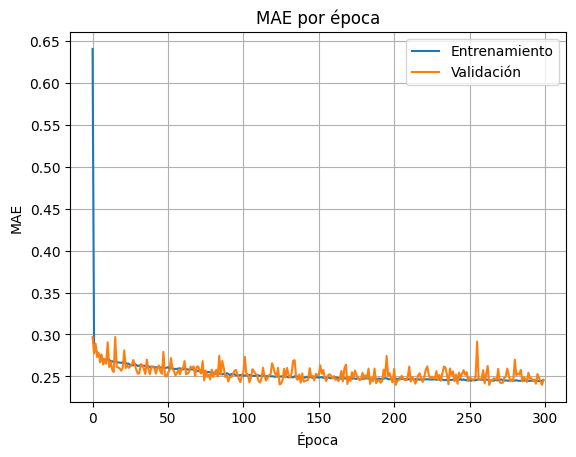

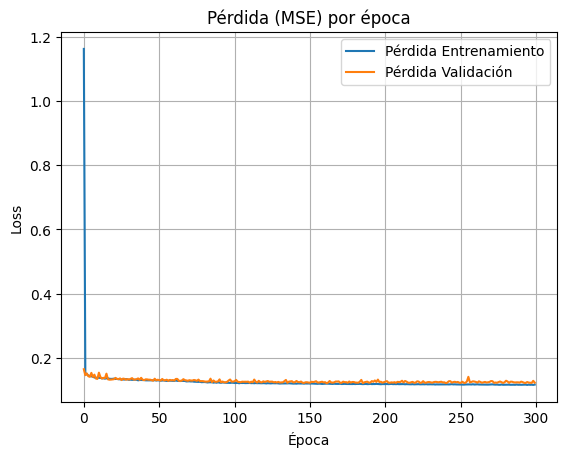

In [ ]:
# Evaluar modelo en conjunto de prueba
loss, mae = model.evaluate(X_test, y_test)
print(f"MAE (Error absoluto medio): {mae:.2f}")

# Gráfico MAE por época
plt.plot(history.history['mae'], label='Entrenamiento')
plt.plot(history.history['val_mae'], label='Validación')
plt.title('MAE por época')
plt.xlabel('Época')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()
print(" ")
# Gráfico de pérdida (MSE)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.title('Pérdida (MSE) por época')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
def predecir_magnitud(latitud, longitud, año, mes, profundidad, columnas_esperadas, scaler, model):
    # Crear diccionario con valores
    nuevo = {
        'latitud': latitud,
        'longitud': longitud,
        'año': año,
        'mes': mes
    }

    # Codificación One-Hot para la profundidad
    profundidades_posibles = ['Superficial', 'Intermedio', 'Profundo']
    for tipo in profundidades_posibles:
        col = f'tipo_profundidad_{tipo}'
        nuevo[col] = 1 if profundidad == tipo else 0

    # Convertir a DataFrame y asegurar mismo orden de columnas
    df_nuevo = pd.DataFrame([nuevo])
    df_nuevo = df_nuevo[columnas_esperadas]

    # Escalar y predecir
    df_scaled = scaler.transform(df_nuevo)
    pred = model.predict(df_scaled)

    return pred[0][0]


In [ ]:
# Predecir magnitud para un nuevo punto
magnitud_estimada = predecir_magnitud(
    latitud = -20.1,
    longitud = -77.0,
    año = 2024,
    mes = 7,
    profundidad = 'Intermedio',  # puede ser también 'Superficial' o 'Profundo'
    columnas_esperadas = columnas_esperadas,
    scaler = scaler,
    model = model
)

print(f"Magnitud estimada: {magnitud_estimada:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Magnitud estimada: 6.27
